# Entrenamiento y validación v4: p discretizadas + topología conjunta

Este notebook entrena el modelo, lo valida con **topología real** (techo de la parte de p) y con **inferencia realista** (topología predicha), y muestra todas las métricas relevantes para las separaciones `p1…p12`.

**Antes de ejecutar**

1. Sustituye en `core/` los archivos `model.py`, `losses.py`, `training.py` y `evaluation.py` por los nuevos. `config.py`, `dataset.py` y `postprocess.py` **no cambian**.
2. Copia también `core/diagnostico_p.py` (opcional, para los diagnósticos).
3. Ajusta `DATA_PATH` y, si quieres, el diccionario `CFG` de la sección 1.

**Qué se compara.** `CFG["model"] = "v3"` reproduce tu modelo anterior (regresión de p). `"v4"` usa la cabeza discretizada de 5 mm. La sección 18 ejecuta una ablación escalonada (A→E) con varias semillas, que es lo que de verdad dice qué cambio ayuda. El test tiene 480 filas, así que diferencias de ±1,5 puntos son ruido.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import copy
import random
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupShuffleSplit, train_test_split

from core.config import *
from core.dataset import (
    Preprocessor,
    ConnectionDataset,
    validate_connection_targets,
    validate_transition_labels,
)
from core.model import ConnectionDesignNet, ConnectionDesignNetV4, n_bins_from_train, p_confidence
from core.losses import ConnectionDesignLoss, ConnectionDesignLossV4
from core.training import fit, predict_loader
from core.evaluation import (
    preparar_para_evaluar,
    evaluar_predicciones,
    evaluar_estructura,
    evaluar_sesgo_p,
    evaluar_acumulado_y,
    evaluar_por_transicion,
    resumen_p,
    contribucion_error_topologia,
    calibracion_confianza_p,
)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)

## 1. Configuración

`CFG` define el experimento principal:

| clave | valores | efecto |
|---|---|---|
| `model` | `"v3"` / `"v4"` | v3 = regresión de p (tu modelo anterior); v4 = p discretizada en bins de 5 mm |
| `joint_topology` | `True` / `False` | solo v4: una softmax conjunta sobre (n_alma, n_cantonera) |
| `class_weights` | `True` / `False` | pesos inversos a la frecuencia en los conteos. `False` optimiza la exactitud directamente |
| `select_metric` | `"val_loss"`, `"p_and_topology"`, `"p_within_10"`, `"p_mae_mm"`, `"topology_exact"` | criterio para elegir la mejor época (en validación realista). `p_and_topology` = % de p dentro de ±10 mm + % de topología exacta; evita elegir épocas tempranas con buena p pero mala topología |
| `w_p_ce`, `label_scale_bins` | números | peso de la cross-entropy de p y suavizado ordinal de la etiqueta (solo v4) |

In [3]:
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_PATH = Path("data/datos_modelo.parquet")
OUTPUT_DIR = Path("artifacts_v4")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = OUTPUT_DIR / "best_v4.pt"

BATCH_SIZE = 128
EPOCHS = 200
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0

HIDDEN_DIM = 192
NUM_BLOCKS = 3
DROPOUT = 0.10
GRU_HIDDEN_DIM = 128

DEFAULT_CFG = dict(
    model="v4",
    joint_topology=True,
    class_weights=False,
    select_metric="p_and_topology",
    w_p_ce=2.0,
    label_scale_bins=1.0,
)
CFG = {**DEFAULT_CFG}          # <- edita aqui el experimento principal

RUN_DIAGNOSTICS = True         # cierre geometrico, multimodalidad, duplicados
USE_DERIVED_FEATURES = False   # ratios M/d (experimental)
RUN_ABLATION = True           # seccion 18 (tarda: 5 configuraciones x semillas)
ABLATION_SEEDS = [0, 1, 2]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Dispositivo:", DEVICE)
print("Experimento :", CFG)

Dispositivo: cpu
Experimento : {'model': 'v4', 'joint_topology': True, 'class_weights': False, 'select_metric': 'p_and_topology', 'w_p_ce': 2.0, 'label_scale_bins': 1.0}


## 2. Carga y validación del dataset

In [4]:
suffix = DATA_PATH.suffix.lower()
if suffix == ".parquet":
    df = pd.read_parquet(DATA_PATH)
elif suffix == ".csv":
    df = pd.read_csv(DATA_PATH)
elif suffix in {".xlsx", ".xls"}:
    df = pd.read_excel(DATA_PATH)
else:
    raise ValueError(f"Formato no soportado: {suffix}")

df = df.reset_index(drop=True)
print("Dimensiones:", df.shape)

Dimensiones: (4671, 56)


In [5]:
required_columns = (
    CATEGORICAL_FEATURES + NUMERIC_FEATURES + REGRESSION_ALWAYS + MASKED_COLUMNS
    + ["standard", "Bolt", "SlipCritical", "n_alma", "n_cantonera"]
)
missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Faltan columnas obligatorias: {missing}")

numeric_columns = list(dict.fromkeys(
    NUMERIC_FEATURES + REGRESSION_ALWAYS + MASKED_COLUMNS + ["n_alma", "n_cantonera"]
))
for c in numeric_columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df[MASKED_COLUMNS] = df[MASKED_COLUMNS].fillna(0.0)
essential = CATEGORICAL_FEATURES + NUMERIC_FEATURES + REGRESSION_ALWAYS + [
    "standard", "Bolt", "SlipCritical", "n_alma", "n_cantonera"
]
before = len(df)
df = df.dropna(subset=essential).reset_index(drop=True)
print(f"Filas eliminadas por nulos: {before - len(df)}")

bolt_numeric = df["Bolt"].astype(str).str.replace("M", "", regex=False).astype(int)
unknown_bolts = sorted(set(bolt_numeric) - set(CATALOGO_BOLT))
if unknown_bolts:
    raise ValueError(f"Bolt fuera de catalogo: {unknown_bolts}")

cv = validate_connection_targets(df)
print("Conexiones con prefijo y conteo coherentes:", cv["valid"].mean())
if not cv["valid"].all():
    df = df.loc[cv["valid"].to_numpy()].reset_index(drop=True)

lv = validate_transition_labels(df)
if lv is not None:
    print("Etiquetas de transicion coherentes:", lv.mean())
    if not lv.all():
        raise ValueError("Hay etiquetas de transicion incompatibles con la topologia.")
else:
    print("No hay columnas pX_transition: se derivan de n_alma y n_cantonera.")

# La cabeza v4 asume que las p estan en una rejilla de Y_GRID_STEP mm.
vals = df[P_COLUMNS].to_numpy(float)
act = vals > 0
on_grid = np.mean(np.isclose(vals[act] % Y_GRID_STEP, 0) | np.isclose(vals[act] % Y_GRID_STEP, Y_GRID_STEP))
print(f"p activas en rejilla de {Y_GRID_STEP} mm: {100 * on_grid:.1f}%  (si es < ~98% revisa la rejilla)")
print("Filas finales:", len(df))

Filas eliminadas por nulos: 0
Conexiones con prefijo y conteo coherentes: 1.0
Etiquetas de transicion coherentes: 1.0
p activas en rejilla de 5 mm: 98.2%  (si es < ~98% revisa la rejilla)
Filas finales: 4671


## 3. Características derivadas (opcional)

Si activas `USE_DERIVED_FEATURES`, se añaden ratios de demanda frente al canto. Para añadir **propiedades de perfil** (`tf`, `tw`, `bf`, `Wpl` de viga y columna) haz lo mismo: une la tabla de perfiles a `df` creando las columnas y añádelas a `NUMERIC_FEATURES` **antes** de crear el `Preprocessor`.

```python
df = df.merge(tabla_perfiles_viga, on=["BEAM_type", "BEAM_d_mm"], how="left")
NUMERIC_FEATURES.extend(["BEAM_tf_mm", "BEAM_tw_mm", "BEAM_bf_mm"])
```

In [6]:
if USE_DERIVED_FEATURES:
    df["M_over_beam_d"] = df["Capacity_Moment"] / df["BEAM_d_mm"]
    df["M_over_col_d"] = df["Capacity_Moment"] / df["COLUMN_d_mm"]
    df["V_over_beam_d"] = df["Capacity_Shear"] / df["BEAM_d_mm"]
    for c in ["M_over_beam_d", "M_over_col_d", "V_over_beam_d"]:
        df[c] = df[c].replace([np.inf, -np.inf], np.nan).fillna(0.0)
        if c not in NUMERIC_FEATURES:
            NUMERIC_FEATURES.append(c)   # modifica la lista compartida con core.dataset
print("Numericas de entrada:", len(NUMERIC_FEATURES), NUMERIC_FEATURES)

Numericas de entrada: 10 ['BEAM_d_mm', 'COLUMN_d_mm', 'fy_acero_mpa', 'fu_acero_mpa', 'fy_tornillo_mpa', 'fu_tornillo_mpa', 'fv_tornillo_mpa', 'ratio_moment', 'ratio_shear', 'ratio_axial']


## 4. División entrenamiento / validación / prueba (por `Unicode`)

In [7]:
GROUP_COLUMN = "Unicode" if "Unicode" in df.columns else None

if GROUP_COLUMN is not None:
    split_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    tv_idx, test_idx = next(split_test.split(df, groups=df[GROUP_COLUMN]))
    df_train_val = df.iloc[tv_idx].reset_index(drop=True)
    df_test = df.iloc[test_idx].reset_index(drop=True)
    split_val = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=SEED)
    tr_idx, va_idx = next(split_val.split(df_train_val, groups=df_train_val[GROUP_COLUMN]))
    df_train = df_train_val.iloc[tr_idx].reset_index(drop=True)
    df_val = df_train_val.iloc[va_idx].reset_index(drop=True)
    assert set(df_train[GROUP_COLUMN]).isdisjoint(set(df_val[GROUP_COLUMN]))
    assert set(df_train[GROUP_COLUMN]).isdisjoint(set(df_test[GROUP_COLUMN]))
else:
    df_train_val, df_test = train_test_split(df, test_size=0.15, random_state=SEED)
    df_train, df_val = train_test_split(df_train_val, test_size=0.1765, random_state=SEED)
    df_train, df_val, df_test = [d.reset_index(drop=True) for d in (df_train, df_val, df_test)]

print("Train:", len(df_train), "| Val:", len(df_val), "| Test:", len(df_test))

for name, other in [("validacion", df_val), ("test", df_test)]:
    unk = {c: sorted(set(other[c].astype(str)) - set(df_train[c].astype(str))) for c in CATEGORICAL_FEATURES}
    unk = {c: v for c, v in unk.items() if v}
    print(f"Categorias desconocidas en {name}:", unk)
    if unk:
        raise ValueError("LabelEncoder no admite categorias desconocidas.")

Train: 3269 | Val: 701 | Test: 701
Categorias desconocidas en validacion: {}
Categorias desconocidas en test: {}


## 5. Diagnósticos previos (sobre entrenamiento)

- **Cierre geométrico**: si `e + Σp + d` es casi función exacta de `BEAM_d_mm` (residuo de pocos mm), existe una restricción que el modelo no conoce y conviene parametrizar las p como fracciones de ese total.
- **Multimodalidad**: si `top3_pct` es alto, las p son casi categóricas y la regresión a la media es mala idea.
- **Duplicados de entrada**: mide el suelo de ruido irreducible.

In [8]:
if RUN_DIAGNOSTICS:
    try:
        from core.diagnostico_p import cierre_geometrico, multimodalidad, duplicados_entrada
        print("CIERRE GEOMETRICO (filas 'todas' primero)")
        cg = cierre_geometrico(df_train)
        display(cg[cg.grupo == "todas"])
        print("MULTIMODALIDAD POR TRANSICION")
        display(multimodalidad(df_train))
        print("SUELO DE RUIDO (entradas identicas)")
        display(duplicados_entrada(df_train))
    except ImportError:
        print("core/diagnostico_p.py no encontrado: se omiten los diagnosticos.")

CIERRE GEOMETRICO (filas 'todas' primero)


,total,grupo,N,pendiente,residuo_std_mm,residuo_MAE_mm,pct_residuo_<=5mm
0,sum(p),todas,3269,1.66,132.49,120.61,0.0
12,e + sum(p),todas,3269,1.69,132.56,120.55,0.0
24,e + sum(p) + d,todas,3269,1.73,131.73,119.43,0.0


MULTIMODALIDAD POR TRANSICION


,transicion,N,valores_distintos,media,std,pct_en_rejilla_5,top1_pct,top3_pct
11,superior__viga primero,3240,34,116.92,23.24,98.98,13.33,34.66
26,viga primero__viga inferior,1890,44,99.13,36.09,97.99,14.55,33.65
23,viga inferior__inferior,1528,20,118.01,23.96,100.00,14.99,39.27
22,viga inferior__cantonera primero,1321,52,166.75,45.31,97.88,10.45,25.66
6,cantonera inferior__inferior,1321,33,136.24,22.09,97.88,14.69,41.64
24,viga primero__viga centro,1100,27,107.21,36.04,100.00,10.27,28.55
20,viga centro__viga inferior,1100,43,129.68,47.89,100.00,11.45,27.36
9,cantonera primero__cantonera inferior,996,29,86.84,26.66,97.19,17.67,41.97
5,cantonera centro__inferior,392,13,117.18,11.85,100.00,43.11,71.43
21,viga inferior__cantonera centro,391,17,130.92,26.56,100.00,22.51,56.78


SUELO DE RUIDO (entradas identicas)


,p,N_en_duplicados,MAE_vs_mediana_grupo_mm,pct_dentro_10mm
0,p1,83,6.14,78.31
1,p2,83,11.27,48.19
2,p3,83,21.63,24.10
3,p4,55,30.05,29.09
4,p5,33,33.18,30.30
5,p6,10,43.25,20.00
6,p7,5,37.50,40.00
7,p8,2,5.00,100.00


## 6. Preprocesador, datasets y loaders

In [9]:
pre = Preprocessor().fit(df_train)
train_dataset = ConnectionDataset(df_train, pre)
val_dataset = ConnectionDataset(df_val, pre)
test_dataset = ConnectionDataset(df_test, pre)

loader_kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kw)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kw)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kw)

N_BINS = n_bins_from_train(df_train, P_COLUMNS, step_mm=Y_GRID_STEP)
print(f"Bins de p: {N_BINS} (hasta {(N_BINS - 1) * Y_GRID_STEP} mm, paso {Y_GRID_STEP} mm)")

Bins de p: 65 (hasta 320 mm, paso 5 mm)


In [10]:
train_loader.dataset[0]

{'x_cat': tensor([0, 0, 0, 1]),
 'x_num': tensor([ 0.2658,  0.3498, -1.5395, -1.5395, -0.9726, -1.0426,  0.3520, -1.1261,
          0.7231, -0.4932]),
 'standard_idx': tensor(2),
 'bolt_idx': tensor(5),
 'slip_critical': tensor(0.),
 'n_alma_idx': tensor(3),
 'n_cantonera_idx': tensor(0),
 'reg_always': tensor([0.6936, 0.8317, 1.2808, 1.3373, 0.4705]),
 'masked_value': tensor([ 1.0019e+00, -2.1748e-01, -8.5349e-01,  3.2751e-01, -3.6811e+00,
         -3.0626e+00, -4.3010e+00, -5.4841e+00, -5.8651e+00, -7.2903e+00,
         -1.3000e+08, -1.6000e+08, -2.8028e+00, -5.4079e-01, -2.8833e+00,
         -4.6707e-01]),
 'masked_mask': tensor([1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 1.]),
 'p_transition_idx': tensor([15, 29, 25, 28,  0,  0,  0,  0,  0,  0,  0,  0]),
 'beam_d_mm': tensor(350.)}

## 7. Construcción del modelo, decodificación y utilidades

In [11]:
def build_experiment(cfg):
    model_kw = dict(
        cat_cardinalities=pre.cat_cardinalities,
        num_continuous=len(NUMERIC_FEATURES),
        n_standard_classes=pre.n_standard_classes,
        p_mean_mm=pre.masked_mean[:N_Y],
        p_std_mm=pre.masked_std[:N_Y],
        hidden_dim=HIDDEN_DIM,
        num_blocks=NUM_BLOCKS,
        dropout=DROPOUT,
        gru_hidden_dim=GRU_HIDDEN_DIM,
        previous_p_scale_mm=200.0,
        cumulative_scale_mm=1000.0,
    )
    w_alma = pre.count_class_weights["n_alma"] if cfg["class_weights"] else np.ones(N_ALMA_CLASSES, np.float32)
    w_cant = pre.count_class_weights["n_cantonera"] if cfg["class_weights"] else np.ones(N_CANTONERA_CLASSES, np.float32)
    loss_kw = dict(
        n_alma_weights=w_alma,
        n_cantonera_weights=w_cant,
        presence_pos_weight=pre.presence_pos_weight,
        p_mean_mm=pre.masked_mean[:N_Y],
        p_std_mm=pre.masked_std[:N_Y],
        w_cls=1.0, w_counts=1.0, w_reg=1.0,
        w_p_value=2.0, w_p_cumulative=0.1,
        w_stiffener_value=1.0, w_masked_presence=0.5,
        cumulative_scale_mm=20.0, p_tolerance_mm=10.0,
    )
    if cfg["model"] == "v3":
        model = ConnectionDesignNet(**model_kw)
        criterion = ConnectionDesignLoss(**loss_kw)
    elif cfg["model"] == "v4":
        model = ConnectionDesignNetV4(**model_kw, n_p_bins=N_BINS, p_bin_step_mm=Y_GRID_STEP,
                                      joint_topology=cfg["joint_topology"])
        criterion = ConnectionDesignLossV4(**loss_kw, n_p_bins=N_BINS, p_bin_step_mm=Y_GRID_STEP,
                                           joint_topology=cfg["joint_topology"],
                                           w_p_ce=cfg["w_p_ce"], label_scale_bins=cfg["label_scale_bins"])
    else:
        raise ValueError(cfg["model"])
    return model.to(DEVICE), criterion.to(DEVICE)


CATALOGS = {"g": CATALOGO_g, "e": CATALOGO_e, "d": CATALOGO_d, "Bp": CATALOGO_Bp, "tp": CATALOGO_tp,
            "tws": CATALOGO_tws, "ts": CATALOGO_ts, "tbs": CATALOGO_tbs, "tst": CATALOGO_tst}


def sigmoid_np(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30.0, 30.0)))


def snap_to_catalog(values, catalog):
    values = np.asarray(values, dtype=float)
    if catalog is None:
        return values
    catalog = np.asarray(catalog, dtype=float)
    return catalog[np.abs(values[:, None] - catalog[None, :]).argmin(axis=1)]


def decode_outputs(outputs, preprocessor):
    reg = preprocessor.inverse_reg_always(outputs["reg_always"])
    masked = preprocessor.inverse_masked(outputs["masked_value"])
    presence = sigmoid_np(outputs["masked_presence_logit"])
    n_alma = outputs["n_alma_logits"].argmax(axis=1)
    n_cantonera = outputs["n_cantonera_logits"].argmax(axis=1)
    k = n_alma + n_cantonera + 1

    result = {}
    for j, name in enumerate(REGRESSION_ALWAYS):
        result[name] = snap_to_catalog(reg[:, j], CATALOGS[name])

    p = np.maximum(np.round(masked[:, :N_Y] / Y_GRID_STEP) * Y_GRID_STEP, Y_GRID_STEP)
    active = np.arange(N_Y)[None, :] < k[:, None]
    p = np.where(active, p, 0.0)
    for j, name in enumerate(P_COLUMNS):
        result[name] = p[:, j]

    for j, name in enumerate(STIFFENER_COLUMNS):
        values = snap_to_catalog(masked[:, N_Y + j], CATALOGS[name])
        result[name] = np.where(presence[:, N_Y + j] >= 0.5, values, 0.0)

    result["Bolt"] = np.asarray(CATALOGO_BOLT)[outputs["bolt_logits"].argmax(axis=1)]
    result["standard"] = preprocessor.standard_encoder.classes_[outputs["standard_logits"].argmax(axis=1)]
    result["SlipCritical"] = np.where(sigmoid_np(outputs["slip_critical_logit"]) >= 0.5, "YES", "NO")
    result["n_alma"] = n_alma
    result["n_cantonera"] = n_cantonera
    result["Hole"] = result["Bolt"] + 2
    result["num_filas_tornillos"] = n_alma + n_cantonera + 2
    result["tiene_cantonera"] = n_cantonera > 0
    return pd.DataFrame(result)


def predict_designs(model, loader):
    out_true = predict_loader(model, loader, DEVICE, use_true_transitions=True)
    out_real = predict_loader(model, loader, DEVICE, use_true_transitions=False)
    return out_true, out_real, decode_outputs(out_true, pre), decode_outputs(out_real, pre)


def kpis(design_real, design_true):
    r = resumen_p(df_test, design_real)
    t = resumen_p(df_test, design_true)
    ok = ((df_test["n_alma"].astype(int).to_numpy() == design_real["n_alma"].astype(int).to_numpy())
          & (df_test["n_cantonera"].astype(int).to_numpy() == design_real["n_cantonera"].astype(int).to_numpy()))
    return {
        "p_MAE_mm": r["MAE_mm"],
        "p_pct_10mm": r["pct_<=10mm"],
        "p_pct_>20mm": r["pct_>20mm"],
        "p99_mm": r["p99_abs_mm"],
        "topologia_exacta_%": 100 * ok.mean(),
        "p_pct_10mm_topologia_real": t["pct_<=10mm"],
    }

## 8. Prueba de una pasada antes de entrenar

In [12]:
set_seed(SEED)
model, criterion = build_experiment(CFG)
print(f"Parametros entrenables: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

sample = next(iter(train_loader))
x_cat = sample["x_cat"].to(DEVICE)
x_num = sample["x_num"].to(DEVICE)
targets = {k: v.to(DEVICE) for k, v in sample.items() if k not in {"x_cat", "x_num"}}
with torch.no_grad():
    out = model(
        x_cat, x_num,
        p_transition_idx=targets["p_transition_idx"],
        p_teacher=targets["masked_value"][:, :N_Y],
        active_count=targets["n_alma_idx"] + targets["n_cantonera_idx"] + 1,
        teacher_forcing_ratio=1.0,
    )
    loss0, parts0 = criterion(out, targets)
print("Loss inicial:", float(loss0))
for k, v in out.items():
    print(f"{k:28s}", tuple(v.shape))

Parametros entrenables: 524,594
Loss inicial: 17.47975730895996
standard_logits              (128, 3)
bolt_logits                  (128, 7)
slip_critical_logit          (128,)
n_alma_logits                (128, 7)
n_cantonera_logits           (128, 6)
reg_always                   (128, 5)
masked_value                 (128, 16)
masked_presence_logit        (128, 16)
p_transition_idx_used        (128, 12)
p_logits                     (128, 12, 65)
topology_logits              (128, 42)


## 9. Entrenamiento

La mejor época se elige con `CFG["select_metric"]` sobre **validación realista** (topología predicha, sin teacher forcing).

In [13]:
print(DATA_PATH.resolve(), pd.Timestamp(DATA_PATH.stat().st_mtime, unit="s"))
print(df.shape)
print(df["grado_acero"].value_counts())
print(df["clase_tornillo"].value_counts())
print(df["standard"].value_counts())

C:\Users\aarbona\OneDrive - Tecnicas Reunidas, S.A\Documentos\proyecto_uniones\V11\data\datos_modelo.parquet 2026-10-15 10:37:47.678709745
(4671, 56)
grado_acero
S355JR    3305
S275JR    1366
Name: count, dtype: int64
clase_tornillo
10.9     2104
8.8      1366
A325M    1201
Name: count, dtype: int64
standard
EN 1993-1-8       2585
AISC-360-05/10    1805
CSA S16-09         281
Name: count, dtype: int64


In [14]:
set_seed(SEED)
model, criterion = build_experiment(CFG)
t0 = time.time()
history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    device=DEVICE,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    checkpoint_path=BEST_CHECKPOINT,
    log_every=10,
    tf_start=1.0,
    tf_end=0.15,
    tf_warmup_fraction=0.15,
    select_metric=CFG["select_metric"],
)
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

Epoca 001/200 | LR 8.53e-05 | TF 100.0% | Train  16.1715 | Val  15.5695 | Mejor  15.5695 [MEJOR] | sel=p_and_topology
  p       | loss train/val 641026.740/833333.875 | CE  4.099/ 4.038 | acumulada  8.798/ 4.894 | MAE  33.86 mm | <=10 mm  27.2%
  geometria | MAE acumulado  71.24 mm | reg  0.401 | rigidizadores  0.324 | presencia  0.822
  topologia | n_alma  1.756 | n_cantonera  1.627 | conjunta  3.393 | exacta  24.5%
  clases  | standard  0.731 | bolt  1.768 | slip  0.465
Epoca 002/200 | LR 1.01e-04 | TF 100.0% | Train  13.9509 | Val  12.8843 | Mejor  12.8843 [MEJOR] | sel=p_and_topology
  p       | loss train/val 769231.138/833333.753 | CE  3.900/ 3.780 | acumulada  3.463/ 3.590 | MAE  28.98 mm | <=10 mm  30.7%
  geometria | MAE acumulado  59.91 mm | reg  0.285 | rigidizadores  0.245 | presencia  0.678
  topologia | n_alma  1.186 | n_cantonera  1.150 | conjunta  2.615 | exacta  41.2%
  clases  | standard  0.283 | bolt  1.334 | slip  0.223
Epoca 003/200 | LR 1.27e-04 | TF 100.0% | Trai

## 10. Curvas de entrenamiento

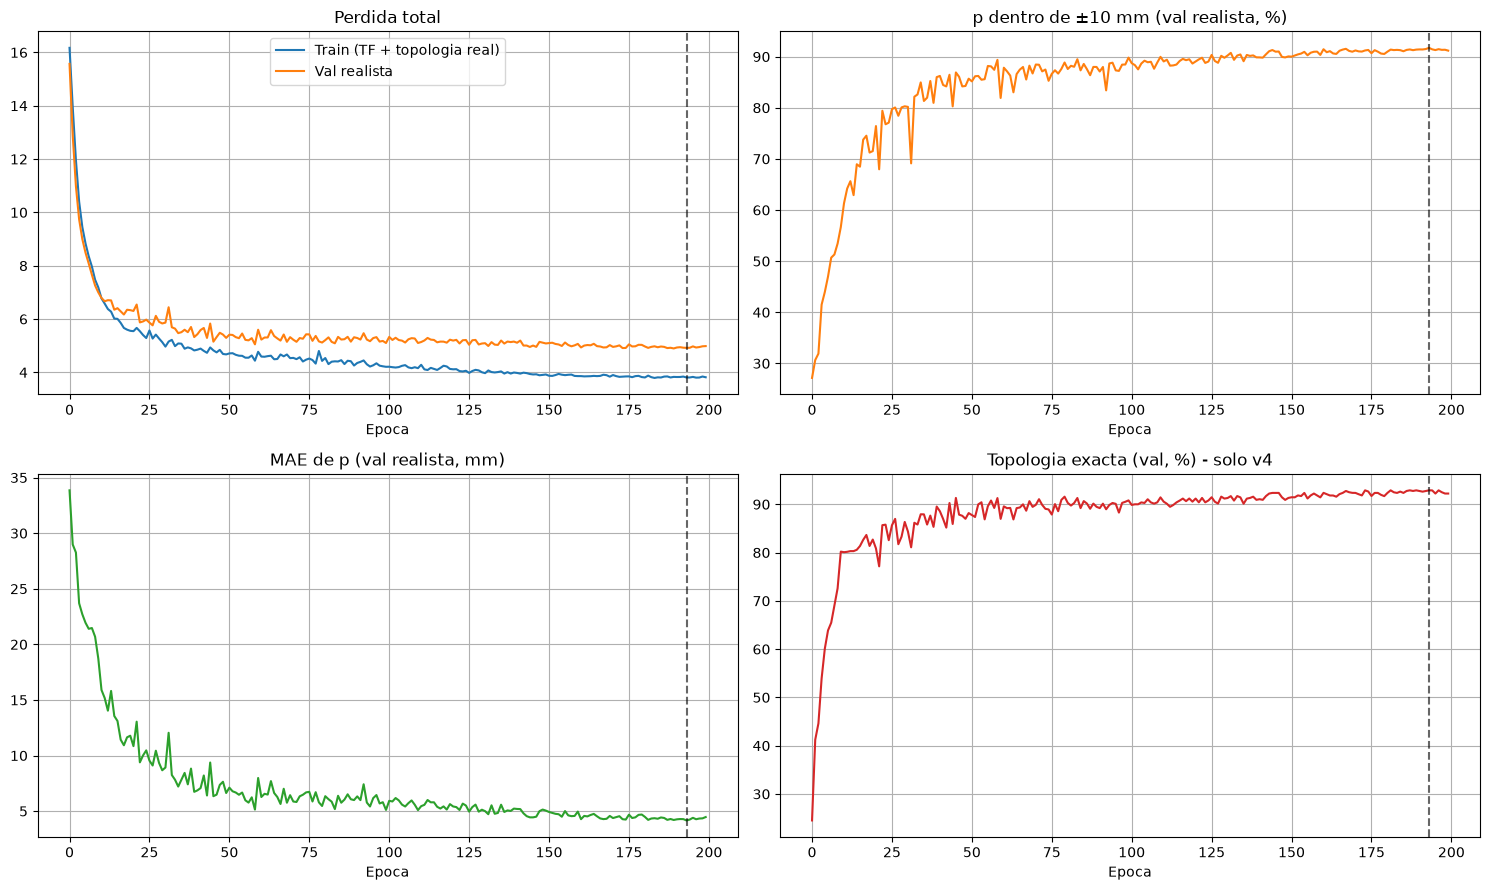

Mejor epoca: 194 | criterio: p_and_topology


In [15]:
def curve(key, scale=1.0):
    return [scale * x.get(key, np.nan) for x in history["val_parts"]]

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
ax[0, 0].plot(history["train_loss"], label="Train (TF + topologia real)")
ax[0, 0].plot(history["val_loss"], label="Val realista")
ax[0, 0].set_title("Perdida total"); ax[0, 0].legend()
ax[0, 1].plot(curve("p_within_10", 100), color="tab:orange")
ax[0, 1].set_title("p dentro de ±10 mm (val realista, %)")
ax[1, 0].plot(curve("p_mae_mm"), color="tab:green")
ax[1, 0].set_title("MAE de p (val realista, mm)")
ax[1, 1].plot(curve("topology_exact", 100), color="tab:red")
ax[1, 1].set_title("Topologia exacta (val, %) - solo v4")
for a in ax.ravel():
    a.axvline(history["best_epoch"] - 1, color="black", linestyle="--", alpha=0.6)
    a.set_xlabel("Epoca"); a.grid(True)
plt.tight_layout(); plt.show()
print("Mejor epoca:", history["best_epoch"], "| criterio:", history["select_metric"])

## 11. Predicción en test: topología real y realista

In [16]:
out_true, out_real, design_true, design_real = predict_designs(model, test_loader)
display(design_real.head())

,g,e,d,Bp,tp,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12,tws,ts,tbs,tst,Bolt,standard,SlipCritical,n_alma,n_cantonera,Hole,num_filas_tornillos,tiene_cantonera
0,140.0,50.0,59.574047,324.0,30.0,160.0,125.0,125.0,215.0,150.0,160.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,12.0,12.0,30,EN 1993-1-8,NO,3,2,32,7,True
1,115.0,40.0,41.571720,260.0,20.0,90.0,65.0,65.0,90.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,10.0,0.0,20,AISC-360-05/10,NO,3,0,22,5,False
2,140.0,50.0,50.421871,226.0,20.0,105.0,80.0,105.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,10.0,24,EN 1993-1-8,NO,2,0,26,4,False
3,140.0,50.0,51.477379,296.0,25.0,120.0,130.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,0.0,0.0,27,EN 1993-1-8,NO,2,0,29,4,False
4,115.0,40.0,47.821243,190.0,20.0,120.0,80.0,80.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,10.0,24,EN 1993-1-8,NO,3,0,26,5,False


In [17]:
design_true.columns

Index(['g', 'e', 'd', 'Bp', 'tp', 'p1', 'p2', 'p3', 'p4', 'p5', 'p6', 'p7', 'p8', 'p9', 'p10', 'p11', 'p12', 'tws', 'ts', 'tbs', 'tst', 'Bolt', 'standard', 'SlipCritical', 'n_alma', 'n_cantonera', 'Hole',
       'num_filas_tornillos', 'tiene_cantonera'],
      dtype='str')

## 12. Métricas de p

Tres lecturas:

- **topología real** = lo que da la parte de p cuando la estructura está bien (techo);
- **inferencia realista** = lo que verá el usuario final;
- **colas** (`pct_>20mm`, `p95`, `p99`): ahí está el problema de fiabilidad.

In [18]:
summary = pd.DataFrame({
    "topologia real": resumen_p(df_test, design_true),
    "inferencia realista": resumen_p(df_test, design_real),
})
display(summary.round(2))

,topologia real,inferencia realista
N_separaciones,3224.00,3224.00
MAE_mm,3.04,5.18
RMSE_mm,14.46,20.93
mediana_abs_mm,0.00,0.00
pct_<=5mm,92.34,89.55
pct_<=10mm,94.57,91.69
pct_>20mm,3.13,5.92
p95_abs_mm,15.00,35.00
p99_abs_mm,90.00,110.00


In [19]:
print("=== TOPOLOGIA REAL ===")
real_df, pred_df = preparar_para_evaluar(df_test, design_true)
metrics_true = evaluar_predicciones(real_df, pred_df)

print("\n=== INFERENCIA REALISTA ===")
real_df, pred_df = preparar_para_evaluar(df_test, design_real)
metrics_realistic = evaluar_predicciones(real_df, pred_df)

=== TOPOLOGIA REAL ===
Variable   N  MAE_mm  RMSE_mm     R2  pct_5mm  pct_10mm
       g 701   2.825    5.116  0.895   86.876    95.578
       e 701   0.350    1.523  0.925   99.144    99.857
       d 701   1.369    2.409  0.916   94.864    98.431
      Bp 701   5.170   10.033  0.962   71.755    88.730
      tp 701   0.884    2.359  0.810   98.431    99.857
      p1 701   1.752    6.086  0.929   92.154    95.435
      p2 701   2.192    9.748  0.938   93.010    95.007
      p3 692   2.340   11.389  0.930   93.642    95.231
      p4 490   3.117   16.855  0.836   93.673    94.898
      p5 317   4.346   17.834  0.679   91.167    93.060
      p6 183  11.481   35.010  0.410   85.246    87.432
      p7  72   4.514   19.248  0.643   90.278    94.444
      p8  37   1.216    3.389  0.987   89.189   100.000
      p9  18   0.833    2.635  0.986   94.444   100.000
     p10  11   1.818    6.030  0.869   90.909    90.909
     p11   1   0.000    0.000    NaN  100.000   100.000
     p12   1   0.000    0

## 13. Topología: exactitud, confusión y contribución al error de p

In [20]:
print("Exactitud de estructura:")
structure = evaluar_estructura(df_test, design_real)

real_na = df_test["n_alma"].astype(int).reset_index(drop=True)
real_nc = df_test["n_cantonera"].astype(int).reset_index(drop=True)
print("\nConfusion n_alma")
display(pd.crosstab(real_na.rename("real"), design_real["n_alma"].astype(int).rename("pred")))
print("Confusion n_cantonera")
display(pd.crosstab(real_nc.rename("real"), design_real["n_cantonera"].astype(int).rename("pred")))

print("Contribucion de la topologia al error de p")
topology_contribution = contribucion_error_topologia(df_test, design_real)
display(topology_contribution.round(2))

Exactitud de estructura:
n_alma_exacto         0.961484
n_cantonera_exacto    0.945792
ambos_exactos         0.921541

Confusion n_alma


pred,1,2,3,4,5,6
real,,,,,,
1,10,0,0,0,0,0
2,0,380,15,2,0,0
3,0,9,226,0,0,0
4,0,0,0,35,0,0
5,0,0,0,1,22,0
6,0,0,0,0,0,1


Confusion n_cantonera


pred,0,1,2,3,4,5
real,,,,,,
0,316,1,8,1,0,0
1,3,68,9,0,0,0
2,10,1,216,3,0,0
3,0,0,2,46,0,0
4,0,0,0,0,16,0
5,0,0,0,0,0,1


Contribucion de la topologia al error de p


,grupo,n_conexiones,n_separaciones,MAE_mm,pct_<=10mm,pct_<=20mm,pct_del_error_total
0,topologia correcta,646,2966,1.10,97.51,99.16,19.6
1,topologia incorrecta,55,258,52.09,24.81,35.66,80.4


## 14. Sesgo, posición acumulada y transiciones

In [21]:
bias_table = evaluar_sesgo_p(df_test, design_real)
print("Sesgo por p (inferencia realista)")
display(bias_table.round(2))

position_table = evaluar_acumulado_y(df_test, design_real, incluir_e=True)
print("Error de posicion acumulada absoluta (incluye e)")
display(position_table.round(2))

transition_summary, transition_detail = evaluar_por_transicion(df_test, design_real)
print("Por transicion (peores primero)")
display(transition_summary.round(2))

Sesgo por p (inferencia realista)


,Variable,N,MAE_mm,sesgo_mm,subestimadas_pct,subestimadas_mas_10_pct
0,p1,701,1.75,-0.06,7.56,2.43
1,p2,701,5.03,-2.00,7.56,4.56
2,p3,692,5.51,0.18,6.21,4.34
3,p4,490,6.43,-3.47,10.00,7.76
4,p5,317,7.17,-3.02,11.67,7.26
5,p6,183,12.44,-9.99,16.39,10.93
6,p7,72,4.79,-4.24,15.28,6.94
7,p8,37,1.89,-1.89,16.22,2.70
8,p9,18,0.83,-0.28,5.56,0.00
9,p10,11,1.82,-1.82,9.09,9.09


Error de posicion acumulada absoluta (incluye e)


,Y_hasta,N,MAE_acumulado_mm,pct_10mm,pct_20mm
0,p1,701,2.06,94.29,98.15
1,p2,701,6.53,90.44,93.30
2,p3,692,8.02,90.03,93.06
3,p4,490,10.62,85.10,89.39
4,p5,317,14.77,81.70,88.64
5,p6,183,20.21,77.05,86.34
6,p7,72,7.67,84.72,88.89
7,p8,37,4.86,81.08,94.59
8,p9,18,2.50,94.44,94.44
9,p10,11,2.27,90.91,90.91


Por transicion (peores primero)


,transicion,N,MAE_mm,sesgo_mm,dentro_10_pct,subestimadas_mas_10_pct
22,viga inferior__cantonera primero,295,8.30,-4.41,84.75,10.51
5,cantonera centro__inferior,80,10.62,-8.88,85.00,12.50
7,cantonera primero__cantonera centro,48,5.35,2.44,85.42,4.17
21,viga inferior__cantonera centro,79,9.49,-8.73,86.08,13.92
9,cantonera primero__cantonera inferior,230,8.15,-0.47,86.96,6.52
6,cantonera inferior__inferior,295,10.54,-9.82,87.80,11.19
20,viga centro__viga inferior,235,5.98,2.23,90.64,3.40
26,viga primero__viga inferior,397,5.83,-4.89,91.94,6.55
24,viga primero__viga centro,235,4.87,2.53,92.34,2.13
4,cantonera centro__cantonera inferior,48,4.08,-1.00,93.75,4.17


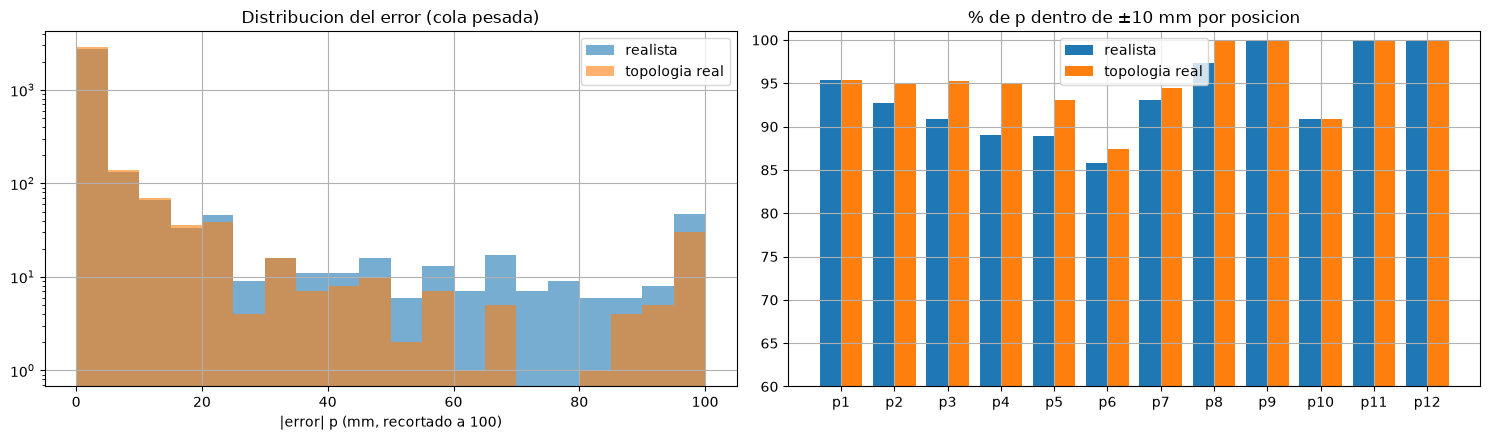

In [22]:
real_matrix = df_test[P_COLUMNS].fillna(0.0).to_numpy(float)
pred_matrix_r = design_real[P_COLUMNS].to_numpy(float)
pred_matrix_t = design_true[P_COLUMNS].to_numpy(float)
active_m = real_matrix > 0

err_r = np.abs(pred_matrix_r - real_matrix)[active_m]
err_t = np.abs(pred_matrix_t - real_matrix)[active_m]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
bins = np.arange(0, 105, 5)
ax[0].hist(np.clip(err_r, 0, 100), bins=bins, alpha=0.6, label="realista")
ax[0].hist(np.clip(err_t, 0, 100), bins=bins, alpha=0.6, label="topologia real")
ax[0].set_yscale("log"); ax[0].set_xlabel("|error| p (mm, recortado a 100)"); ax[0].set_title("Distribucion del error (cola pesada)")
ax[0].legend(); ax[0].grid(True)

pct_r = [100 * np.mean(np.abs(pred_matrix_r[active_m[:, j], j] - real_matrix[active_m[:, j], j]) <= 10) if active_m[:, j].any() else np.nan for j in range(N_Y)]
pct_t = [100 * np.mean(np.abs(pred_matrix_t[active_m[:, j], j] - real_matrix[active_m[:, j], j]) <= 10) if active_m[:, j].any() else np.nan for j in range(N_Y)]
x = np.arange(N_Y)
ax[1].bar(x - 0.2, pct_r, 0.4, label="realista")
ax[1].bar(x + 0.2, pct_t, 0.4, label="topologia real")
ax[1].set_xticks(x); ax[1].set_xticklabels(P_COLUMNS); ax[1].set_ylim(60, 101)
ax[1].set_title("% de p dentro de ±10 mm por posicion"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()

## 15. Casos extremos

In [23]:
abs_err = np.abs(pred_matrix_r - real_matrix)
abs_err[~active_m] = np.nan
extreme = pd.DataFrame({
    "indice_test": np.arange(len(df_test)),
    "max_error_mm": np.nanmax(abs_err, axis=1),
    "mean_error_mm": np.nanmean(abs_err, axis=1),
    "peor_p": np.nanargmax(abs_err, axis=1) + 1,
    "n_alma_real": df_test["n_alma"].astype(int).to_numpy(),
    "n_alma_pred": design_real["n_alma"].astype(int).to_numpy(),
    "n_cantonera_real": df_test["n_cantonera"].astype(int).to_numpy(),
    "n_cantonera_pred": design_real["n_cantonera"].astype(int).to_numpy(),
})
extreme["topologia_correcta"] = (
    (extreme.n_alma_real == extreme.n_alma_pred) & (extreme.n_cantonera_real == extreme.n_cantonera_pred)
)
extreme = extreme.sort_values("max_error_mm", ascending=False)
display(extreme.head(25).round(2))
print("Entre las 40 peores conexiones, con topologia incorrecta:", int((~extreme.head(40).topologia_correcta).sum()))

,indice_test,max_error_mm,mean_error_mm,peor_p,n_alma_real,n_alma_pred,n_cantonera_real,n_cantonera_pred,topologia_correcta
414,414,315.0,135.00,2,2,4,0,0,False
268,268,315.0,135.00,2,2,4,0,0,False
439,439,190.0,95.00,4,3,2,0,0,False
640,640,180.0,78.00,3,2,3,2,2,False
218,218,169.6,57.77,2,2,3,2,3,False
283,283,160.0,68.57,2,3,2,3,2,False
5,5,155.0,81.67,2,2,3,0,3,False
353,353,145.0,56.25,4,2,2,1,0,False
140,140,145.0,51.25,4,2,2,1,0,False
182,182,145.0,60.00,5,3,3,2,0,False


Entre las 40 peores conexiones, con topologia incorrecta: 37


## 16. Confianza de las p (solo v4) y triaje

La cabeza discreta devuelve una distribución por separación. `prob_dentro_10` es la masa de probabilidad a ≤ ±10 mm de la moda. Si está bien calibrada, sirve para **marcar conexiones que un ingeniero debería revisar**.

In [24]:
if CFG["model"] == "v4":
    p_mode_prob, p_prob10 = p_confidence(out_real["p_logits"])
    print("Calibracion (tramo de confianza predicha vs acierto real <=10 mm)")
    display(calibracion_confianza_p(df_test, design_real, p_prob10).round(2))

    k_pred = design_real["n_alma"].astype(int).to_numpy() + design_real["n_cantonera"].astype(int).to_numpy() + 1
    active_pred = np.arange(N_Y)[None, :] < k_pred[:, None]
    conn_conf = np.where(active_pred, p_prob10, 1.0).min(axis=1)

    topo_ok = ((df_test["n_alma"].astype(int).to_numpy() == design_real["n_alma"].astype(int).to_numpy())
               & (df_test["n_cantonera"].astype(int).to_numpy() == design_real["n_cantonera"].astype(int).to_numpy()))
    all_p_ok = np.all((np.abs(pred_matrix_r - real_matrix) <= 10) | ~active_m, axis=1) & topo_ok

    rows = []
    for thr in [0.5, 0.7, 0.85, 0.95]:
        flagged = conn_conf < thr
        rows.append({
            "umbral_confianza": thr,
            "% conexiones marcadas para revision": 100 * flagged.mean(),
            "% correctas entre las NO marcadas": 100 * all_p_ok[~flagged].mean() if (~flagged).any() else np.nan,
            "% correctas global": 100 * all_p_ok.mean(),
        })
    print("Triaje: conexion correcta = topologia correcta y todas las p dentro de ±10 mm")
    display(pd.DataFrame(rows).round(1))
else:
    print("Modelo v3: no hay distribucion por p, se omite la confianza.")

Calibracion (tramo de confianza predicha vs acierto real <=10 mm)


,confianza_predicha,N,prob_media_predicha_%,acierto_real_<=10mm_%
0,"[0.00, 0.50]",35,41.910000,25.71
1,"[0.50, 0.70]",149,61.290001,53.02
2,"[0.70, 0.85]",296,79.040001,74.66
3,"[0.85, 0.95]",2704,92.110001,96.45
4,"[0.95, 1.00]",40,95.599998,97.50


Triaje: conexion correcta = topologia correcta y todas las p dentro de ±10 mm


,umbral_confianza,% conexiones marcadas para revision,% correctas entre las NO marcadas,% correctas global
0,0.5,3.3,88.9,86.6
1,0.7,14.3,93.2,86.6
2,0.8,31.5,97.1,86.6
3,1.0,100.0,NaN,86.6


## 17. Guardado de artefactos

In [25]:
FINAL_MODEL_PATH = OUTPUT_DIR / "model_final.pt"
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "cfg": CFG,
        "best_epoch": history["best_epoch"],
        "n_p_bins": N_BINS,
        "p_bin_step_mm": Y_GRID_STEP,
        "cat_cardinalities": pre.cat_cardinalities,
        "numeric_features": list(NUMERIC_FEATURES),
        "n_standard_classes": pre.n_standard_classes,
        "hidden_dim": HIDDEN_DIM, "num_blocks": NUM_BLOCKS, "dropout": DROPOUT, "gru_hidden_dim": GRU_HIDDEN_DIM,
        "p_mean_mm": pre.masked_mean[:N_Y], "p_std_mm": pre.masked_std[:N_Y],
    },
    FINAL_MODEL_PATH,
)
joblib.dump(pre, OUTPUT_DIR / "preprocessor.joblib")
joblib.dump(history, OUTPUT_DIR / "history.joblib")
design_real.to_parquet(OUTPUT_DIR / "test_predictions.parquet", index=False)

with pd.ExcelWriter(OUTPUT_DIR / "metricas.xlsx", engine="openpyxl") as writer:
    summary.to_excel(writer, sheet_name="resumen_p")
    metrics_true.to_excel(writer, sheet_name="topologia_real", index=False)
    metrics_realistic.to_excel(writer, sheet_name="inferencia_realista", index=False)
    topology_contribution.to_excel(writer, sheet_name="contribucion_topologia", index=False)
    bias_table.to_excel(writer, sheet_name="sesgo_p", index=False)
    position_table.to_excel(writer, sheet_name="posicion_acumulada", index=False)
    transition_summary.to_excel(writer, sheet_name="transiciones", index=False)
    extreme.to_excel(writer, sheet_name="casos_extremos", index=False)
print("Artefactos en:", OUTPUT_DIR.resolve())

Artefactos en: C:\Users\aarbona\OneDrive - Tecnicas Reunidas, S.A\Documentos\proyecto_uniones\V11\artifacts_v4


## 18. Ablación escalonada con varias semillas (opcional)

Cada paso cambia **una cosa** respecto al anterior:

| | modelo | pesos de clase | topología | selección de época |
|---|---|---|---|---|
| A | v3 original | sí | independiente | `val_loss` |
| B | v3 | **no** | independiente | `val_loss` |
| C | **v4 (p discreta)** | no | independiente | `val_loss` |
| D | v4 | no | **conjunta** | `val_loss` |
| E | v4 | no | conjunta | **`p_and_topology`** |

Activa `RUN_ABLATION = True` en la sección 1. Con 3 semillas son 15 entrenamientos: en CPU puede tardar bastante, así que reduce `EPOCHS` si solo quieres una comparación rápida. Las semillas cambian la inicialización y el orden de los lotes, no la partición de datos.

In [26]:
# ABLATION_CONFIGS = {
#     "A_v3_original": {**DEFAULT_CFG, "model": "v3", "joint_topology": False, "class_weights": True, "select_metric": "val_loss"},
#     "B_v3_sin_pesos": {**DEFAULT_CFG, "model": "v3", "joint_topology": False, "class_weights": False, "select_metric": "val_loss"},
#     "C_v4_p_discreta": {**DEFAULT_CFG, "model": "v4", "joint_topology": False, "class_weights": False, "select_metric": "val_loss"},
#     "D_v4_topologia_conjunta": {**DEFAULT_CFG, "model": "v4", "joint_topology": True, "class_weights": False, "select_metric": "val_loss"},
#     "E_v4_seleccion_por_p": {**DEFAULT_CFG, "model": "v4", "joint_topology": True, "class_weights": False, "select_metric": "p_and_topology"},
# }

# ablation_rows = []
# if RUN_ABLATION:
#     for name, cfg in ABLATION_CONFIGS.items():
#         for seed in ABLATION_SEEDS:
#             set_seed(seed)
#             m, crit = build_experiment(cfg)
#             fit(m, train_loader, val_loader, crit, DEVICE, epochs=EPOCHS, lr=LEARNING_RATE,
#                 weight_decay=WEIGHT_DECAY, checkpoint_path=None, log_every=10**9,
#                 select_metric=cfg["select_metric"], verbose=False)
#             _, _, d_true, d_real = predict_designs(m, test_loader)
#             ablation_rows.append({"config": name, "seed": seed, **kpis(d_real, d_true)})
#             print(f"{name} seed={seed}: p<=10mm {ablation_rows[-1]['p_pct_10mm']:.1f}% | "
#                   f"topologia {ablation_rows[-1]['topologia_exacta_%']:.1f}%")
#     ablation = pd.DataFrame(ablation_rows)
#     agg = ablation.groupby("config").agg(["mean", "std"]).drop(columns="seed")
#     display(agg.round(2))
#     ablation.to_csv(OUTPUT_DIR / "ablacion.csv", index=False)
# else:
#     print("RUN_ABLATION=False: omitida.")